# 01 Data collection: satellite PM2.5, population and boundaries

Collects every raw input the project needs and saves it with only two changes: each PM2.5 grid is cropped to a box around Bangladesh, and its variable is renamed to `pm25`. Values are not touched, so every later number can be traced back to a dated source file.

**Sources (all open, no account needed)**
- **ACAG satellite-derived PM2.5** (SatPM2.5, Washington University in St. Louis): annual mean PM2.5 at 0.01° (about 1 km) and monthly mean PM2.5 at 0.1° (about 10 km), from 1998, in µg/m³. Read from the AWS Open Data copy (`s3://satpmdata`), licence CC BY 4.0. The newest V6 release is used (V6.GL.03 runs 1998 to 2024). Its 0.01° files are split by region, so only the Asia file is downloaded
- **WorldPop 2022 population counts** (R2025A, constrained, 100 m): people per cell, used as the weights for population-weighted exposure
- **HDX Bangladesh administrative boundaries** (BBS, COD-AB): divisions, districts and upazilas, with geoBoundaries as a fallback

**Why crop on download:** even the Asia file is about 90 MB, but Bangladesh is a small box inside it. Each file goes to the Colab machine's temporary disk, gets cropped, and is deleted, so only small Bangladesh files reach Drive.

**Why annual at 0.01° but monthly at 0.1°:** the annual files carry the fine spatial detail for district and upazila exposure, trends and hotspots. Seasonality only needs the monthly shape, so the coarse monthly files are used when the release has them.

**Outputs**
- `data/raw/boundaries/`: the boundary download as published
- `data/raw/worldpop/bgd_pop_2022_CN_100m_R2025A_v1.tif`
- `data/raw/pm25/annual/pm25_annual_YYYY.nc` (one file per year, 0.01°)
- `data/raw/pm25/monthly/pm25_monthly_YYYY.nc` (one file per year, 12 months each, 0.1° or 0.01°)
- `data/parquet/pm25_s3_listing.parquet`, `data/raw/download_manifest.csv`

**Where files are saved:** in Colab, the setup cell mounts Google Drive and writes into `My Drive/Bangladesh Air Pollution Project/data/`. Run locally, it uses the project folder one level above `notebooks/`.

**Rerunning:** every download is skipped when its output file already exists, so if Colab disconnects halfway, just run all cells again and it carries on where it stopped.

Nothing is cleaned here. Aligning the grids, population weighting and zonal means happen in notebook 02.

In [1]:
%pip install -q rioxarray netCDF4 h5netcdf pyogrio

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.4/72.4 kB 2.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.6/10.6 MB 61.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 79.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 84.0 MB/s eta 0:00:00


In [2]:
import requests, pandas as pd, xarray as xr, geopandas as gpd, rioxarray, pyogrio, pathlib, zipfile, shutil, tempfile, os, re, datetime as dt
import xml.etree.ElementTree as ET, matplotlib.pyplot as plt
from urllib.parse import quote
from tqdm.auto import tqdm

try:
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = pathlib.Path("/content/drive/MyDrive/Bangladesh Air Pollution Project")
except ImportError:
    ROOT = pathlib.Path.cwd().parent

assert (ROOT / "notebooks").exists(), f"Project folder not found at {ROOT}"
RAW, PARQUET = ROOT / "data" / "raw", ROOT / "data" / "parquet"
PM_ANN, PM_MON, POP_DIR, BND_DIR = RAW / "pm25" / "annual", RAW / "pm25" / "monthly", RAW / "worldpop", RAW / "boundaries"
TMP = pathlib.Path(tempfile.gettempdir()) / "pm25_tmp"
for d in (PM_ANN, PM_MON, POP_DIR, BND_DIR, PARQUET, TMP):
    d.mkdir(parents=True, exist_ok=True)

os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"
RUN_DATE = dt.date.today().isoformat()
HEADERS = {"User-Agent": "Mozilla/5.0 (research download; contact: ashiqurrahmankhan04@gmail.com)"}
W, E, S, N = 87.9, 92.8, 20.5, 26.7
manifest = []

def download(url, path):
    with requests.get(url, headers=HEADERS, stream=True, timeout=300) as r:
        r.raise_for_status()
        with open(path, "wb") as f:
            for chunk in r.iter_content(1 << 22):
                f.write(chunk)
    return path

Mounted at /content/drive


## 1. Administrative boundaries (HDX, BBS COD-AB)

**Why HDX:** it hosts the official BBS boundaries used by the UN in Bangladesh, at three levels: 8 divisions, 64 districts and the upazila level (495 upazilas plus 12 city corporation units in the current version). The dataset's file list is read from the HDX API, so a renamed file does not break the notebook. If HDX is down, the same three levels come from geoBoundaries instead.

**Spelling note:** some district names in these files may use the pre-2018 spellings (Chittagong, Barisal, Comilla, Jessore, Bogra). They are kept as published here and harmonised in notebook 02.

In [3]:
try:
    res = pd.DataFrame(requests.get("https://data.humdata.org/api/3/action/package_show?id=cod-ab-bgd", headers=HEADERS, timeout=60).json()["result"]["resources"])
    display(res[["name", "format", "url"]])
    pick = res[res["format"].str.contains("geopackage|gpkg", case=False)]
    pick = pick if len(pick) else res[res["format"].str.contains("shp|shapefile", case=False)]
    url = pick.iloc[0]["url"]
    bnd_file = BND_DIR / url.split("/")[-1].split("?")[0]
    if not bnd_file.exists():
        download(url, bnd_file)
    if bnd_file.suffix == ".zip":
        zipfile.ZipFile(bnd_file).extractall(BND_DIR / bnd_file.stem)
    manifest.append({"source": "hdx_cod_ab_bgd", "item": bnd_file.name, "status": "ok", "bytes": bnd_file.stat().st_size, "url": url})
except Exception as e:
    print(f"HDX failed ({e}), using geoBoundaries instead")
    for lvl in (1, 2, 3):
        url = requests.get(f"https://www.geoboundaries.org/api/current/gbOpen/BGD/ADM{lvl}/", timeout=60).json()["gjDownloadURL"]
        path = download(url, BND_DIR / f"geoBoundaries_BGD_ADM{lvl}.geojson")
        manifest.append({"source": "geoboundaries", "item": path.name, "status": "ok", "bytes": path.stat().st_size, "url": url})

,name,format,url
0,bgd_admin_boundaries.gdb.zip,Geodatabase,https://data.humdata.org/dataset/401d3fae-4262...
1,bgd_admin_boundaries.shp.zip,SHP,https://data.humdata.org/dataset/401d3fae-4262...
2,bgd_admin_boundaries.geojson.zip,GeoJSON,https://data.humdata.org/dataset/401d3fae-4262...
3,bgd_admin_boundaries.xlsx,XLSX,https://data.humdata.org/dataset/401d3fae-4262...


Every boundary layer found in the download, with its feature count. Look for one layer with **8** features (divisions), one with **64** (districts) and one with about **507** (upazilas and city corporations). Notebook 02 picks the layers by these counts.

In [4]:
layers = pd.DataFrame([
    {"file": str(p.relative_to(BND_DIR)), "layer": l, "features": (info := pyogrio.read_info(p, layer=l))["features"], "geometry": info["geometry_type"], "crs": info["crs"], "fields": ", ".join(info["fields"][:8])}
    for p in sorted([*BND_DIR.rglob("*.gpkg"), *BND_DIR.rglob("*.shp"), *BND_DIR.rglob("*.geojson")])
    for l in pyogrio.list_layers(p)[:, 0]
])
layers.to_csv(BND_DIR / "layer_summary.csv", index=False)
layers

,file,layer,features,geometry,crs,fields
0,bgd_admin_boundaries.shp,bgd_admin3,507,Polygon,EPSG:4326,"adm3_name, adm3_name1, adm3_name2, adm3_name3,..."
1,bgd_admin_boundaries.shp,bgd_adminlines,2916,LineString,EPSG:4326,"adm_level, name, valid_on, valid_to, version, ..."
2,bgd_admin_boundaries.shp,bgd_admin1,8,Polygon,EPSG:4326,"adm1_name, adm1_name1, adm1_name2, adm1_name3,..."
3,bgd_admin_boundaries.shp,bgd_admin0,1,Polygon,EPSG:4326,"iso2, iso3, adm0_name, adm0_name1, adm0_name2,..."
4,bgd_admin_boundaries.shp,bgd_admin2,64,Polygon,EPSG:4326,"adm2_name, adm2_name1, adm2_name2, adm2_name3,..."
5,bgd_admin_boundaries.shp,bgd_admincapitals,507,Point,EPSG:4326,"adm_p_lvl, name, name_1, name_2, name_3, loc_p..."
6,bgd_admin_boundaries.shp,bgd_adminpoints,5777,Point,EPSG:4326,"admin_leve, name, name1, name2, name3, x_coord..."
7,bgd_admin_boundaries.shp/bgd_admin0.shp,bgd_admin0,1,Polygon,EPSG:4326,"iso2, iso3, adm0_name, adm0_name1, adm0_name2,..."
8,bgd_admin_boundaries.shp/bgd_admin1.shp,bgd_admin1,8,Polygon,EPSG:4326,"adm1_name, adm1_name1, adm1_name2, adm1_name3,..."
9,bgd_admin_boundaries.shp/bgd_admin2.shp,bgd_admin2,64,Polygon,EPSG:4326,"adm2_name, adm2_name1, adm2_name2, adm2_name3,..."


Districts: 64, bounds: [88.01 20.59 92.68 26.63]


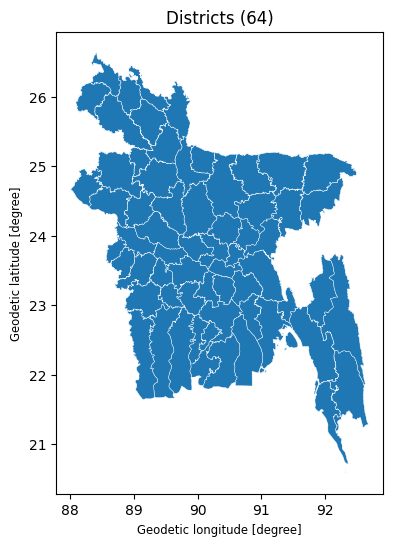

In [5]:
row = layers.loc[layers["features"] == 64].iloc[0]
districts = gpd.read_file(BND_DIR / row["file"], layer=row["layer"]).to_crs(4326)
country = districts.dissolve()
print(f"Districts: {len(districts)}, bounds: {country.total_bounds.round(2)}")
assert W < country.total_bounds[0] and country.total_bounds[2] < E and S < country.total_bounds[1] and country.total_bounds[3] < N, "Bangladesh is not inside the crop box, widen W, E, S, N"
districts.plot(edgecolor="white", linewidth=0.3, figsize=(5, 6)).set_title("Districts (64)");

## 2. Population (WorldPop 2022, 100 m)

**Why WorldPop:** it spreads the census population onto a 100 m grid using buildings, roads and other layers, so exposure can be weighted by where people actually live. A district average of the raw PM2.5 grid would count empty char land and forest as much as Dhaka city.

**Why the constrained version:** it only places people in cells with buildings, which is closer to reality in a country with large rivers and wetlands.

**Why 2022:** it sits near the end of the study period and matches the latest census year. Using one year's population for all years means the trend answers "how did pollution change where people live today", which notebook 02 states as an assumption.

In [6]:
POP_URL = "https://data.worldpop.org/GIS/Population/Global_2015_2030/R2025A/2022/BGD/v1/100m/constrained/bgd_pop_2022_CN_100m_R2025A_v1.tif"
pop_file = POP_DIR / POP_URL.split("/")[-1]
if not pop_file.exists():
    download(POP_URL, pop_file)
pop = rioxarray.open_rasterio(pop_file, masked=True).squeeze()
manifest.append({"source": "worldpop", "item": pop_file.name, "status": "ok", "bytes": pop_file.stat().st_size, "url": POP_URL})
pd.Series({"rows x cols": f"{pop.shape[0]} x {pop.shape[1]}", "crs": str(pop.rio.crs), "cell size (deg)": round(abs(pop.rio.resolution()[0]), 6), "total population": f"{float(pop.sum()):,.0f}", "cells with people": f"{int(pop.notnull().sum()):,}"})

,0
rows x cols,7269 x 5604
crs,EPSG:4326
cell size (deg),0.000833
total population,"168,343,392"
cells with people,"10,351,008"


The total should be roughly 165 to 175 million, in line with the 2022 census (165.2 million enumerated) and later UN estimates.

## 3. PM2.5 file list (AWS Open Data)

**Why AWS and not Box:** the ACAG website links to Box folders, which need clicking in a browser. The same files are on the AWS Registry of Open Data in the public `satpmdata` bucket, which can be listed and downloaded with plain HTTPS, no account or key.

The bucket's file list is read first and saved, so the exact files used are on record. It holds every release since V5 (the older V5 releases use a different, GWR-based method), and the newer releases split the 0.01° files by region (AS, AF, EU and so on). Each file is tagged with its version and region from its folder path. Each file name ends in a `YYYYMM-YYYYMM` period: January to December of one year is an annual file, and the same month at both ends is a monthly file. Coarse 0.1° files sit in a `c0p10` folder. The table shows the V6 releases only.

In [7]:
S3 = "https://satpmdata.s3.amazonaws.com"

def s3_list():
    rows, token = [], None
    while True:
        r = requests.get(S3, params={"list-type": 2, **({"continuation-token": token} if token else {})}, headers=HEADERS, timeout=60)
        r.raise_for_status()
        x = ET.fromstring(r.content)
        ns = {"s": x.tag[1:].split("}")[0]}
        rows += [{"key": c.findtext("s:Key", namespaces=ns), "bytes": int(c.findtext("s:Size", namespaces=ns))} for c in x.findall("s:Contents", ns)]
        if x.findtext("s:IsTruncated", namespaces=ns) != "true":
            return pd.DataFrame(rows)
        token = x.findtext("s:NextContinuationToken", namespaces=ns)

files = s3_list()
files.to_parquet(PARQUET / "pm25_s3_listing.parquet", index=False)
files = (files[files["key"].str.endswith(".nc") & ~files["key"].str.contains("sigma|uncert", case=False)]
         .join(files["key"].str.extract(r"(?P<start>\d{6})-(?P<end>\d{6})\.nc$")).dropna()
         .assign(version=lambda d: d["key"].str.split("/").map(lambda p: next((s for s in p if re.fullmatch(r"V\d[A-Z]{2}\d+", s)), "unknown")),
                 region=lambda d: d["key"].str.extract(r"/(?:Annual|Monthly)/([^/]+)/", expand=False),
                 year=lambda d: d["start"].str[:4].astype(int),
                 period=lambda d: (d["start"] == d["end"]).map({True: "monthly", False: "other"}).where(~((d["start"].str[4:] == "01") & (d["end"].str[4:] == "12") & (d["start"].str[:4] == d["end"].str[:4])), "annual"),
                 grid=lambda d: d["key"].str.contains("0p1").map({True: "0.1 deg", False: "0.01 deg"})))
print(f"{len(files)} PM2.5 files in the bucket")
files[files["version"].str.startswith("V6GL")].groupby(["version", "period", "grid", "region"]).agg(files=("key", "size"), first_year=("year", "min"), last_year=("year", "max"), median_mb=("bytes", lambda b: round(b.median() / 1e6, 1)))

29571 PM2.5 files in the bucket


files  first_year  last_year  median_mb
version  period  grid     region                                         
V6GL01   annual  0.01 deg GL         20        2000       2019      784.7
                 0.1 deg  GL         20        2000       2019       12.6
         monthly 0.01 deg GL        240        2000       2019      513.3
                 0.1 deg  GL        240        2000       2019       11.9
V6GL0204 annual  0.01 deg AS         26        1998       2023       90.8
                          EU         26        1998       2023       28.3
                          GL         26        1998       2023      441.6
                          NA         26        1998       2023       92.4
                 0.1 deg  AS         26        1998       2023        1.1
                          EU         26        1998       2023        0.3
                          GL         26        1998       2023        5.2
                          NA         26        1998       2023        1.1
         monthly 0.01 deg AS        312        1998       2023       93.6
                          EU        312        1998       2023       29.0
                          GL        312        1998       2023      445.2
                          NA        312        1998       2023       91.8
                 0.1 deg  AS        312        1998       2023        1.1
                          EU        312        1998       2023        0.4
                          GL        312        1998       2023        5.3
                          NA        312        1998       2023        1.1
V6GL03   annual  0.01 deg AF         27        1998       2024       86.7
                          AS         27        1998       2024       91.0
                          EU         27        1998       2024       28.3
                          GL         27        1998       2024      443.1
                          NA         27        1998       2024       93.1
                          SA         27        1998       2024       48.9
                 0.1 deg  AF         27        1998       2024        1.0
                          AS         27        1998       2024        1.1
                          EU         27        1998       2024        0.3
                          GL         27        1998       2024        5.2
                          NA         27        1998       2024        1.1
                          SA         27        1998       2024        0.6
         monthly 0.01 deg AF        324        1998       2024       91.0
                          AS        324        1998       2024       93.4
                          EU        324        1998       2024       29.1
                          GL        324        1998       2024      446.8
                          NA        324        1998       2024       92.0
                          SA        324        1998       2024       50.3
                 0.1 deg  AF        324        1998       2024        1.0
                          AS        324        1998       2024        1.1
                          EU        324        1998       2024        0.4
                          GL        324        1998       2024        5.3
                          NA        324        1998       2024        1.1
                          SA        324        1998       2024        0.6

The cell below picks the V6 release whose annual 0.01° files reach the latest year, and for each year takes the Asia file (or the global file if there is no Asia one). One release is used for every year, because mixing releases would create false jumps in the trend. Monthly data comes from the same release: the 0.1° set if it is complete, otherwise the 0.01° Asia files, which are larger to download but end up just as small after cropping. The checks stop the notebook if any year or month is missing, so nothing incomplete gets downloaded.

In [8]:
ASIA = ["AS", "Asia", "GL", "Global"]
pick = lambda v, period, grid: (files.query("version == @v and period == @period and grid == @grid and region in @ASIA")
                                .assign(rank=lambda d: d["region"].map(ASIA.index)).sort_values(["start", "rank"]).drop_duplicates("start"))
VERSION = max([v for v in files.loc[files["version"].str.startswith("V6GL"), "version"].unique() if len(pick(v, "annual", "0.01 deg"))], key=lambda v: (pick(v, "annual", "0.01 deg")["year"].max(), len(pick(v, "annual", "0.01 deg"))))
annual = pick(VERSION, "annual", "0.01 deg").sort_values("year")
YEARS = annual["year"].tolist()
monthly = pick(VERSION, "monthly", "0.1 deg")
if monthly.groupby("year").size().reindex(YEARS).ne(12).any():
    print("No complete 0.1 deg monthly set for this version, using the 0.01 deg monthly files instead (larger downloads, same crop)")
    monthly = pick(VERSION, "monthly", "0.01 deg")
monthly = monthly.query("year in @YEARS").sort_values("start")
assert YEARS[0] == 1998 and YEARS == list(range(1998, YEARS[-1] + 1)), f"{VERSION} annual years are not a continuous run from 1998: {YEARS}"
assert monthly.groupby("year").size().reindex(YEARS).eq(12).all(), f"{VERSION} is missing monthly files for some years"
print(f"Using {VERSION}, {YEARS[0]} to {YEARS[-1]} ({len(YEARS)} years)")
print(f"Annual: {len(annual)} files, region {annual['region'].unique().tolist()}, {annual['bytes'].sum() / 1e9:.1f} GB to stream")
print(f"Monthly: {len(monthly)} files, {monthly['grid'].iloc[0]}, region {monthly['region'].unique().tolist()}, {monthly['bytes'].sum() / 1e9:.1f} GB to stream")

Using V6GL03, 1998 to 2024 (27 years)
Annual: 27 files, region ['AS'], 2.4 GB to stream
Monthly: 324 files, 0.1 deg, region ['AS'], 0.4 GB to stream


## 4. Download and crop

Each file is downloaded to the temporary disk, opened, cropped to the Bangladesh box (87.9 to 92.8°E, 20.5 to 26.7°N), saved, and deleted. The latitude order is checked before cropping because some grids run north to south. The PM2.5 variable is found by name (`pm` in it) and renamed to `pm25`; the source file name is stored inside each output. A check stops the loop if a file does not cover all of Bangladesh.

The progress bars show how fast it is going. If Colab disconnects, rerun all cells and finished years are skipped.

In [9]:
def fetch(key):
    tmp = download(f"{S3}/{quote(key)}", TMP / pathlib.Path(key).name)
    with xr.open_dataset(tmp) as ds:
        ds = ds.rename({k: v for k, v in {"latitude": "lat", "longitude": "lon"}.items() if k in ds.variables})
        var = next(v for v in ds.data_vars if "pm" in v.lower())
        lat = slice(S, N) if ds["lat"][0] < ds["lat"][-1] else slice(N, S)
        da = ds[var].sel(lat=lat, lon=slice(W, E)).squeeze(drop=True).sortby("lat").load().rename("pm25")
    tmp.unlink()
    b = country.total_bounds
    assert da["lon"].min() <= b[0] and da["lon"].max() >= b[2] and da["lat"].min() <= b[1] and da["lat"].max() >= b[3], f"{key} does not cover all of Bangladesh"
    return da.assign_attrs(units="ug/m3", product=f"ACAG {VERSION}", source_file=pathlib.Path(key).name, downloaded=RUN_DATE)

def save(da, out):
    da.to_netcdf(TMP / out.name)
    shutil.move(TMP / out.name, out)
    manifest.append({"source": "acag_satpm", "item": out.name, "status": "ok", "bytes": out.stat().st_size, "url": S3, "source_files": da.attrs["source_file"]})

for _, f in tqdm(annual.iterrows(), total=len(annual), desc="Annual 0.01 deg"):
    out = PM_ANN / f"pm25_annual_{f['year']}.nc"
    if not out.exists():
        save(fetch(f["key"]), out)

Annual 0.01 deg:   0%|          | 0/27 [00:00<?, ?it/s]

In [10]:
for y, g in tqdm(monthly.groupby("year"), desc="Monthly (by year)"):
    out = PM_MON / f"pm25_monthly_{y}.nc"
    if not out.exists():
        da = xr.concat([fetch(k).expand_dims(time=[pd.Timestamp(f"{s[:4]}-{s[4:]}-01")]) for k, s in zip(g["key"], g["start"])], "time")
        save(da.assign_attrs(source_file="; ".join(pathlib.Path(k).name for k in g["key"])), out)
print(f"Annual files: {len(list(PM_ANN.glob('*.nc')))} | Monthly files: {len(list(PM_MON.glob('*.nc')))}")

Monthly (by year):   0%|          | 0/27 [00:00<?, ?it/s]

Annual files: 27 | Monthly files: 27


## 5. First look (raw, before any weighting)

A quick check that the files are complete and sensible before notebook 02 builds on them: grid size, missing cells inside Bangladesh, and the range of values per year. Bangladesh annual means are expected to sit far above the WHO guideline of 5 µg/m³, with the highest values around Dhaka and the north-west in the dry season.

The national figures here are **simple area means inside the border**, not population-weighted. Population weighting is notebook 02's job.

In [11]:
clip = lambda da: da.rio.write_crs(4326).rio.set_spatial_dims("lon", "lat").rio.clip(country.geometry, all_touched=True, drop=True)
ann = xr.concat([xr.open_dataarray(PM_ANN / f"pm25_annual_{y}.nc").expand_dims(year=[y]) for y in YEARS], "year")
ann_bd = clip(ann)
check = pd.DataFrame({
    "grid": f"{ann.sizes['lat']} x {ann.sizes['lon']}",
    "cells_in_bangladesh": int(ann_bd.isel(year=0).notnull().sum()),
    "missing_in_bangladesh_%": (ann_bd.isnull().mean(["lat", "lon"]) * 100).round(2).values,
    "min": ann_bd.min(["lat", "lon"]).round(1).values,
    "area_mean": ann_bd.mean(["lat", "lon"]).round(1).values,
    "max": ann_bd.max(["lat", "lon"]).round(1).values,
}, index=pd.Index(YEARS, name="year"))
check

,grid,cells_in_bangladesh,missing_in_bangladesh_%,min,area_mean,max
year,,,,,,
1998,620 x 490,131901,53.51,11.600000,36.099998,61.299999
1999,620 x 490,131901,53.51,10.800000,38.299999,73.300003
2000,620 x 490,131901,53.51,17.900000,47.099998,73.400002
2001,620 x 490,131901,53.51,17.400000,43.799999,73.000000
2002,620 x 490,131901,53.51,16.700001,45.500000,74.099998
2003,620 x 490,131901,53.51,18.900000,50.000000,76.400002
2004,620 x 490,131901,53.51,20.000000,48.299999,81.199997
2005,620 x 490,131901,53.51,18.100000,48.000000,87.599998
2006,620 x 490,131901,53.51,21.100000,55.599998,87.099998


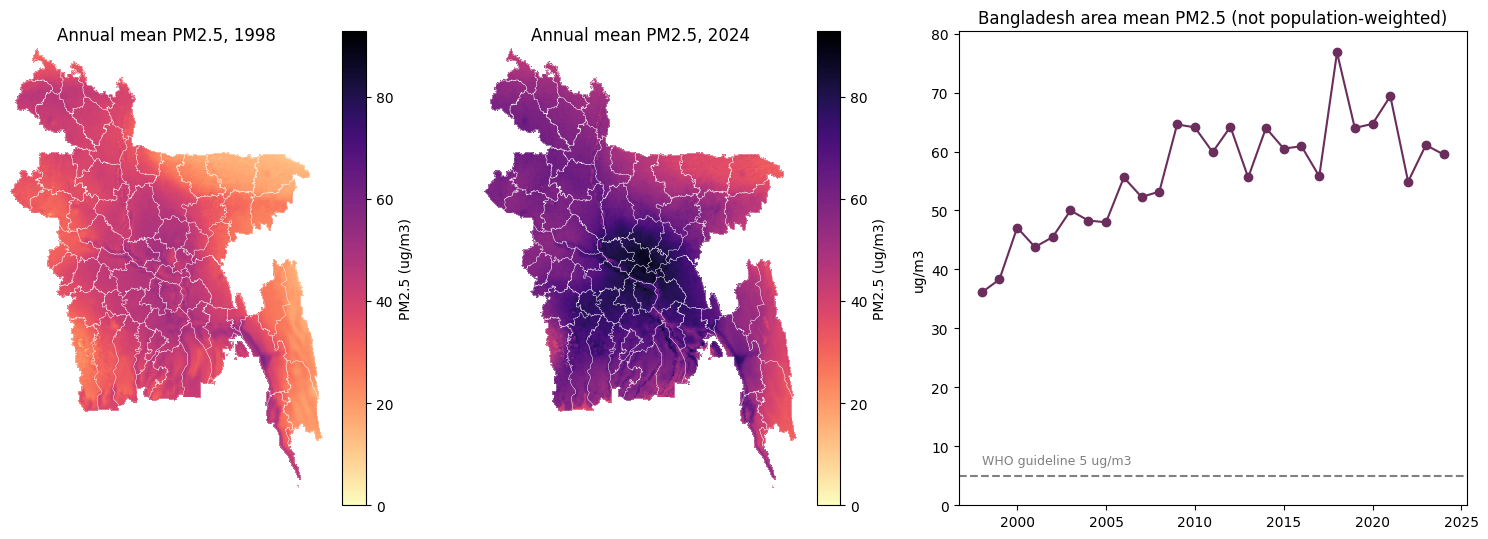

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1, 1.3]})
vmax = float(ann_bd.quantile(0.99))
for a, y in zip(ax[:2], (YEARS[0], YEARS[-1])):
    ann_bd.sel(year=y).plot(ax=a, vmin=0, vmax=vmax, cmap="magma_r", cbar_kwargs={"label": "PM2.5 (ug/m3)"})
    districts.boundary.plot(ax=a, color="white", linewidth=0.2)
    a.set_title(f"Annual mean PM2.5, {y}"); a.set_axis_off()
check["area_mean"].plot(ax=ax[2], marker="o", color="#6b2d5c")
ax[2].axhline(5, ls="--", color="grey"); ax[2].text(1998, 7, "WHO guideline 5 ug/m3", color="grey", fontsize=9)
ax[2].set(title="Bangladesh area mean PM2.5 (not population-weighted)", xlabel="", ylabel="ug/m3", ylim=(0, None))
plt.tight_layout()

Monthly series: Jan 1998 to Dec 2024, 324 months, missing: 0


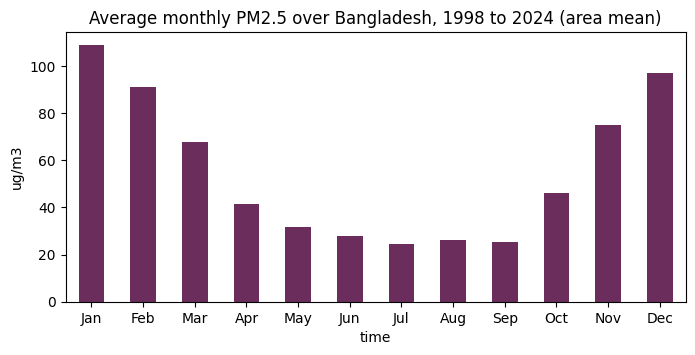

In [13]:
mon = clip(xr.concat([xr.open_dataarray(p) for p in sorted(PM_MON.glob("pm25_monthly_*.nc"))], "time"))
season = mon.mean(["lat", "lon"]).to_series()
print(f"Monthly series: {season.index.min():%b %Y} to {season.index.max():%b %Y}, {len(season)} months, missing: {season.isna().sum()}")
season.groupby(season.index.month).mean().rename(lambda m: pd.Timestamp(2000, m, 1).strftime("%b")).plot(kind="bar", color="#6b2d5c", figsize=(8, 3.5), title=f"Average monthly PM2.5 over Bangladesh, {YEARS[0]} to {YEARS[-1]} (area mean)", ylabel="ug/m3", rot=0);

## Download manifest

In [14]:
pd.DataFrame(manifest).assign(run_date=RUN_DATE).to_csv(RAW / "download_manifest.csv", index=False)
shutil.rmtree(TMP, ignore_errors=True)
pd.DataFrame(manifest).groupby("source").agg(files=("item", "size"), mb=("bytes", lambda b: round(b.sum() / 1e6, 1)))

,files,mb
source,,
acag_satpm,54,25.5
hdx_cod_ab_bgd,1,33.1
worldpop,1,54.9


## Next: notebook 02, raster processing

Pick and harmonise the division, district and upazila layers, align WorldPop to the 0.01° PM2.5 grid, compute population-weighted mean PM2.5 for every upazila, district and division for each year (and each month), count people in each WHO band, and check the national weighted mean against ACAG's own country-level figure.

Covariates for the driver models (Q6 and Q7) are downloaded at the start of notebook 05, where they are first used.